# Prior-date player quality

Stage 03 builds separate batting and bowling quality dimensions from history **strictly before the match date**. It preserves every Stage 02 event and the fixed first-innings-team outcome label. It does not train models, decide live player availability or aggregate remaining resources.

Inputs: verified Stage 01-02 exports and the source participant registries. Processed data: `data/processed/historical_features/`. Reports and figures: `outputs/03_player_quality_features/`.

`RUN_STAGE = True` rebuilds; `False` reads existing hash-verified results. Missing or stale results never trigger an automatic rebuild. `SAVE_FIGURES` only refreshes presentation files.


In [17]:
from pathlib import Path
import importlib
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / 'config' / 'player_quality.json').is_file()
             and (p / 'src' / 'player_quality_features.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the project directory.')
sys.path.insert(0, str(ROOT / 'src'))
import player_quality_features as stage
import player_quality_visualisation as viz
from audit_visualisation import table
importlib.reload(stage)
importlib.reload(viz)

RUN_STAGE = False
SAVE_FIGURES = True
OUTPUT = ROOT / stage.REPORT_DIR
DATA = ROOT / stage.DATA_DIR
print('Project:', ROOT)
print('Python:', sys.executable)
print('pandas:', pd.__version__)


Project: D:\T20_Project\T20_Project_3.0
Python: d:\T20_Project\T20_Project_3.0\.venv\Scripts\python.exe
pandas: 2.3.3


## 1. Build or verify

Stage 03 retains the complete Stage 01 cohort and the Stage 02 event rows and base columns. Profiles cover every source-listed participant, including eventual replacements. **A profile is not proof that a player started or was available at a particular event.** Stage 04 owns that reconstruction.


In [18]:
if RUN_STAGE:
    stage.run(ROOT)
summary = stage.verified_output(ROOT)
profiles = pd.read_csv(DATA / 'player_match_profiles.csv.gz', parse_dates=['match_date', 'history_last_date'])
coverage = pd.read_csv(OUTPUT / 'history_coverage.csv')
role_coverage = pd.read_csv(OUTPUT / 'current_role_coverage.csv')
catalogue_audit = pd.read_csv(OUTPUT / 'participant_catalogue_audit.csv')
aliases = pd.read_csv(OUTPUT / 'player_aliases.csv')
contract = json.loads((OUTPUT / 'feature_contract.json').read_text(encoding='utf-8'))
config = summary['config']
print('Verified quality export:', summary['quality_id'])
print('Upstream Stage 02 feature export:', summary['upstream_feature_id'])
display(table(pd.DataFrame([{'Check': key, 'Passed': value} for key,value in summary['checks'].items()]), 'Export checks', collapsed=True))


Verified quality export: f5ca00d19816ce50dbfea8ad23962809760ae1622322726dcc0d55ae5731e832
Upstream Stage 02 feature export: 23d7cb39fed6eba6d52f75750e6d53a37ffe8aaac2c4f86b376f85e0b905631c


Check,Passed
one_profile_per_listed_player_match,True
profile_cohort_preserved,True
same_event_count,True
same_source_order,True
finite_smoothed_metrics,True
nonnegative_smoothed_metrics,True
nonnegative_prior_counts,True
history_strictly_before_date,True
no_missing_model_features,True
unseen_players_equal_prior_reference,True


## 2. History coverage

Coverage bars count player-match profiles, not unique players. A specialist batter can have no bowling history without being a new player. Current-actor coverage is reported separately, weighted by recorded events.

Displayed 120-ball bands are descriptive and do not exclude anyone. Stable IDs join known history; an unresolved ID stops export rather than silently assigning an average profile.


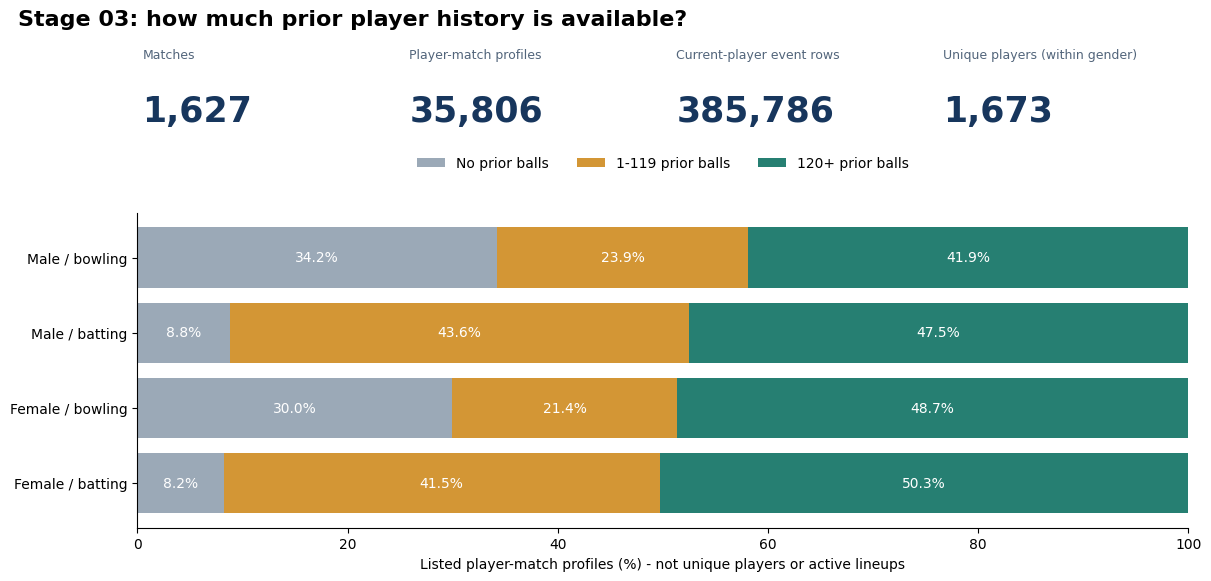

role,gender,events,no_prior_balls_events,no_prior_balls_percent
striker,female,147722,5385,3.645361
striker,male,238064,10775,4.526094
non_striker,female,147722,5234,3.543142
non_striker,male,238064,10774,4.525674
bowler,female,147722,6930,4.691244
bowler,male,238064,14443,6.066856


gender,role,history_band,player_match_profiles,proportion
female,batting,No prior balls,1130,0.081878
female,batting,1-119 prior balls,5730,0.415187
female,batting,120+ prior balls,6941,0.502935
female,bowling,No prior balls,4134,0.299544
female,bowling,1-119 prior balls,2947,0.213535
female,bowling,120+ prior balls,6720,0.486921
male,batting,No prior balls,1944,0.088344
male,batting,1-119 prior balls,9600,0.436264
male,batting,120+ prior balls,10461,0.475392
male,bowling,No prior balls,7529,0.342150


gender,player_id,display_names,distinct_names,listed_matches
female,5230a33d,L Winfield | L Winfield-Hill,2,35
female,6a434bd3,KH Brunt | KH Sciver-Brunt,2,82
female,7c0055c1,KE Broadmore | KE Ebrahim,2,10
female,f3a18a0c,NR Sciver | NR Sciver-Brunt,2,121
male,3086f7a4,Mohammad Nawaz | Mohammad Nawaz (3),2,75


Matches with more than eleven listed participants on at least one side: 11


match_id,gender,team,listed_participants,more_than_eleven_listed
222678,male,New Zealand,12,True
222678,male,South Africa,12,True
1173070,female,India,12,True
1223952,male,India,12,True
1289274,female,India,12,True
1382164,female,Bangladesh,12,True
1388204,female,England,12,True
1425126,male,Zimbabwe,12,True
1432443,female,West Indies,12,True
1434291,female,India,12,True


In [19]:
saved_figures = []
def show_figure(fig, name):
    if SAVE_FIGURES:
        folder = OUTPUT / 'figures'
        folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder / (name + '.png'), dpi=150, facecolor='white')
        saved_figures.append(name + '.png')
    display(fig)
    plt.close(fig)

show_figure(viz.coverage_figure(summary, coverage), 'player_history_coverage')
role_coverage['no_prior_balls_percent'] = 100 * role_coverage.no_prior_balls_events / role_coverage.events
display(table(role_coverage, 'No prior role-specific balls among current actors'))
display(table(coverage, 'Exact listed-profile coverage counts', collapsed=True))
display(table(aliases.loc[aliases.distinct_names.gt(1)], 'Multiple display names linked by stable player ID', collapsed=True))
print('Matches with more than eleven listed participants on at least one side:',
      summary['matches_with_extra_listed_participants'])
display(table(catalogue_audit.loc[catalogue_audit.more_than_eleven_listed],
              'Extra source-listed participants: not added to the active XI here', collapsed=True))


## 3. Metric definitions and smoothing assumptions

Seven dimensions are preserved separately: four batting and three bowling metrics. The wicket metric is credited wickets per legal ball, not balls per wicket, so zero wickets with positive exposure yields a valid raw rate of zero.

For a metric with multiplier M, historical numerator N and exposure D:

- Raw = M * N / D; zero denominator stays NA.
- Prior-date reference R = (M * pooled N + cold-start R0 * Kpool) / (pooled D + Kpool).
- Smoothed player metric = (M * player N + R * Kplayer) / (player D + Kplayer).

Both pooled and player history exclude the entire current date and are gender-specific. Default personal strength is 120 balls or 10 dismissals; population strength is 600 balls or 50 dismissals. These are **prespecified assumptions, not validated optimal settings**. Reference values can differ by date and gender. No full-dataset means or future results are used.

Cold-start average 20, batting strike rate 110, economy 7.5 and wicket rate 1/24 are the prespecified reference values recorded in `config/player_quality.json`. Boundary rate 0.10 and batting/bowling dot rates 0.40 are explicit initial assumptions, not measured population estimates. All values are configurable and recorded; later comparisons must use validation only.


In [20]:
display(table(pd.read_csv(OUTPUT / 'metric_dictionary.csv'), 'Metric definitions'))
settings = [{'Setting': key, 'Value': config[key]} for key in
            ['player_pseudo_balls', 'player_pseudo_dismissals', 'population_pseudo_balls', 'population_pseudo_dismissals']]
display(table(pd.DataFrame(settings), 'Prespecified smoothing strengths'))
display(table(pd.DataFrame([{'Metric': k, 'Cold-start reference': v} for k,v in config['cold_start'].items()]),
              'Cold-start reference values', collapsed=True))
references = pd.read_csv(OUTPUT / 'prior_date_references.csv')
display(table(references.groupby('gender').head(4), 'Earliest prior-date population references', collapsed=True))


metric,definition,numerator,denominator,multiplier,pseudo_unit,raw_zero_denominator,snapshot
batting_strike_rate,Batter runs per 100 non-wide events (no-ball events included).,batting_runs,balls_faced,100.0,balls,Not available,strictly before match date
batting_average,"Batter runs per true dismissal; temporary retirement excluded. No dismissal -> raw NA, not zero.",batting_runs,batting_dismissals,1.0,dismissals,Not available,strictly before match date
batting_boundary_rate,Non-wide events with batter runs 4 or 6 divided by faced events; not boundary-run share.,boundary_balls,balls_faced,1.0,balls,Not available,strictly before match date
batting_dot_rate,Non-wide events with zero batter runs divided by faced events; byes may occur.,batting_dot_balls,balls_faced,1.0,balls,Not available,strictly before match date
bowling_economy,"6*(batter runs + wides + no-ball extras)/legal balls; byes, legbyes and separate penalties excluded.",bowling_runs_conceded,legal_balls_bowled,6.0,balls,Not available,strictly before match date
bowling_wicket_rate,"Bowler-credited dismissals per legal ball; run out, retired out, timed out etc excluded. Not a Bernoulli probability.",bowler_wickets,legal_balls_bowled,1.0,balls,Not available,strictly before match date
bowling_dot_rate,Legal events with zero total runs divided by legal balls; different from batting dot rate.,bowling_dot_balls,legal_balls_bowled,1.0,balls,Not available,strictly before match date


Setting,Value
player_pseudo_balls,120.0
player_pseudo_dismissals,10.0
population_pseudo_balls,600.0
population_pseudo_dismissals,50.0


Metric,Cold-start reference
batting_strike_rate,110.000000
batting_average,20.000000
batting_boundary_rate,0.100000
batting_dot_rate,0.400000
bowling_economy,7.500000
bowling_wicket_rate,0.041667
bowling_dot_rate,0.400000


gender,match_date,reference_batting_strike_rate,reference_batting_average,reference_batting_boundary_rate,reference_batting_dot_rate,reference_bowling_economy,reference_bowling_wicket_rate,reference_bowling_dot_rate,reference_prior_balls_faced,reference_prior_balls_bowled
male,2005-02-17,110.000000,20.000000,0.100000,0.400000,7.500000,0.041667,0.400000,0,0
male,2005-06-13,122.619048,21.076923,0.129762,0.373810,8.035714,0.046429,0.367857,240,240
male,2005-10-21,121.408183,19.469880,0.134158,0.383444,7.902579,0.054441,0.373448,451,447
male,2006-01-09,119.062500,19.020408,0.135156,0.394531,7.731132,0.055818,0.380503,680,672
female,2009-06-18,110.000000,20.000000,0.100000,0.400000,7.500000,0.041667,0.400000,0,0
female,2009-06-19,105.231867,19.140625,0.097503,0.416171,7.035714,0.042857,0.413095,241,240
female,2009-06-25,110.658017,21.605634,0.112141,0.401297,7.281337,0.039926,0.393686,479,477
female,2009-10-28,110.689917,22.500000,0.109932,0.393480,7.170843,0.039484,0.386484,719,717


## 4. Quality distributions

These are distributions of historical feature values, including reference values for players with no relevant history. Repeated player-match snapshots are not independent observations. Higher strike rate is not automatically better overall; this stage does not assign a single player ranking or claim predictive benefit.


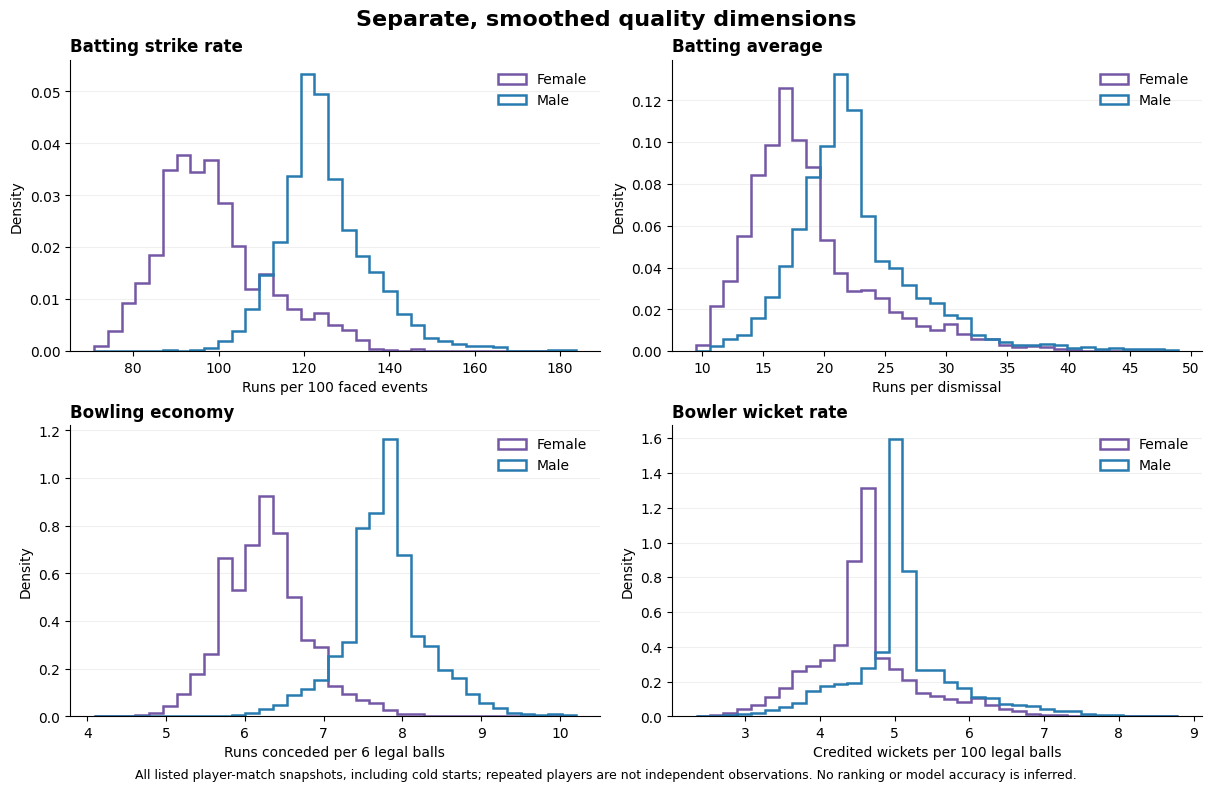

In [21]:
show_figure(viz.distribution_figure(profiles), 'quality_distributions')


## 5. Sparse-history behaviour

The plot uses one earliest snapshot with 1-119 prior faced events per player. Shrinkage reduces reliance on a few observed balls. Colour shows the available evidence; this is not a confidence interval or a guarantee of accuracy.

A player with no observed history receives the prior-date reference and a no-history flag. A known player with no dismissals can still have runs/balls history: raw batting average is undefined, but the regularised estimate is finite.


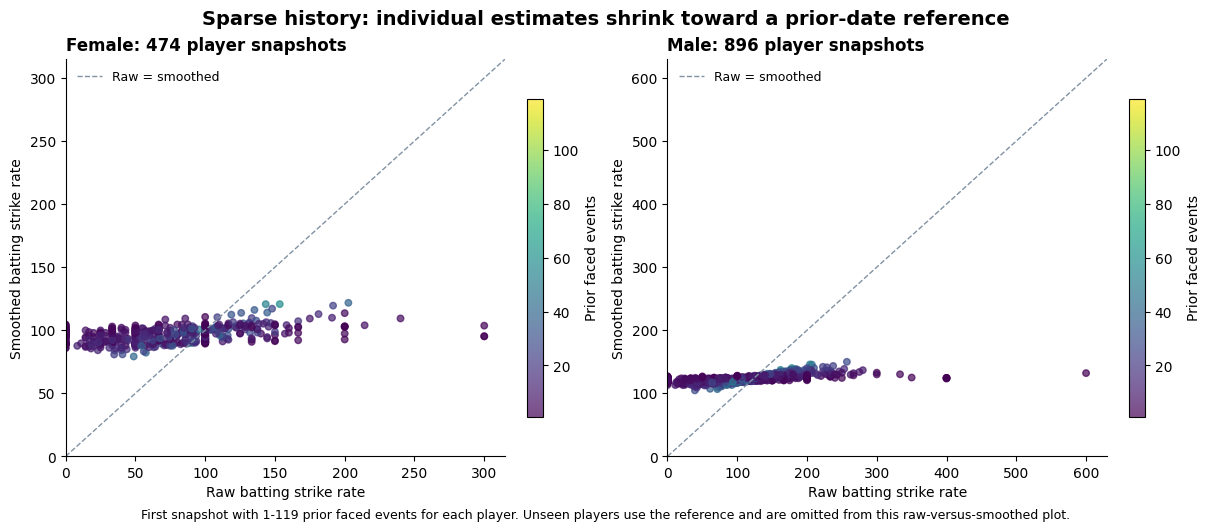

match_id,match_date,gender,player_name,prior_balls_faced,prior_batting_dismissals,raw_batting_strike_rate,reference_batting_strike_rate,smoothed_batting_strike_rate,batting_ball_reliability
211028,2005-06-13,male,AC Gilchrist,3,1,33.333333,122.619048,120.441347,0.024390
211028,2005-06-13,male,MEK Hussey,15,0,206.666667,122.619048,131.957672,0.111111
211028,2005-06-13,male,DR Martyn,5,1,60.000000,122.619048,120.114286,0.040000
211028,2005-06-13,male,RT Ponting,55,0,178.181818,122.619048,140.081633,0.314286
211028,2005-06-13,male,A Symonds,13,1,246.153846,122.619048,134.693878,0.097744
211028,2005-06-13,male,MJ Clarke,4,1,175.000000,122.619048,124.308756,0.032258
222678,2005-10-21,male,AR Adams,7,1,100.000000,121.408183,120.228204,0.055118
222678,2005-10-21,male,SB Styris,39,1,169.230769,121.408183,133.138251,0.245283
222678,2005-10-21,male,HJH Marshall,7,1,114.285714,121.408183,121.015606,0.055118
222678,2005-10-21,male,KD Mills,1,1,0.000000,121.408183,120.404809,0.008264


In [22]:
show_figure(viz.smoothing_figure(profiles), 'sparse_history_smoothing')
examples = profiles.loc[profiles.prior_balls_faced.between(1,119)].sort_values(['match_date','match_id']).drop_duplicates(['gender','player_id']).head(12)
display(table(examples[['match_id','match_date','gender','player_name','prior_balls_faced',
                        'prior_batting_dismissals','raw_batting_strike_rate','reference_batting_strike_rate',
                        'smoothed_batting_strike_rate','batting_ball_reliability']],
              'Sparse-history examples', collapsed=True))


## 6. Current-player quality diagnostics

The export retains four batting metrics for each striker and non-striker, three bowling metrics for the bowler, and eight history-evidence fields for diagnostic inspection. These current-actor fields are **not direct inputs to the current prediction models**. IDs, names, raw diagnostic rates, and future/current event results are not predictors.

Stage 05 uses the shared prior-date player profiles to construct remaining-resource sums. It excludes standalone striker, non-striker and bowler quality and associated evidence from the model-input export and allowlists. Stage 06 compares state/background with batting, bowling and combined resources, not a direct current-player-quality arm.


In [23]:
display(table(pd.DataFrame([
    {'Block': 'Quality dimensions', 'Columns': ', '.join(contract['current_player_quality'])},
    {'Block': 'Evidence accompanying quality', 'Columns': ', '.join(contract['current_player_evidence'])}
]), 'Current-player quality diagnostics - not direct model inputs'))
preview = pd.read_csv(DATA / 'current_player_features.csv.gz', nrows=12)
columns = ['match_id','match_innings','event_sequence','striker','striker_id',
           'striker_smoothed_batting_strike_rate','striker_no_prior_batting_balls',
           'bowler','bowler_id','bowler_smoothed_bowling_economy',
           'bowler_smoothed_bowling_wicket_rate',stage.state.TARGET]
display(table(preview[columns], 'Current actors joined to their prior-date profiles', collapsed=True))


Block,Columns
Quality dimensions,"striker_smoothed_batting_strike_rate, striker_smoothed_batting_average, striker_smoothed_batting_boundary_rate, striker_smoothed_batting_dot_rate, non_striker_smoothed_batting_strike_rate, non_striker_smoothed_batting_average, non_striker_smoothed_batting_boundary_rate, non_striker_smoothed_batting_dot_rate, bowler_smoothed_bowling_economy, bowler_smoothed_bowling_wicket_rate, bowler_smoothed_bowling_dot_rate"
Evidence accompanying quality,"striker_no_prior_batting_balls, striker_batting_ball_reliability, striker_batting_average_reliability, non_striker_no_prior_batting_balls, non_striker_batting_ball_reliability, non_striker_batting_average_reliability, bowler_no_prior_bowling_balls, bowler_bowling_ball_reliability"


match_id,match_innings,event_sequence,striker,striker_id,striker_smoothed_batting_strike_rate,striker_no_prior_batting_balls,bowler,bowler_id,bowler_smoothed_bowling_economy,bowler_smoothed_bowling_wicket_rate,first_batting_team_win
211028,1,1,ME Trescothick,ea42ddb9,122.619048,1,B Lee,dd09ff8e,7.779762,0.045635,1
211028,1,2,ME Trescothick,ea42ddb9,122.619048,1,B Lee,dd09ff8e,7.779762,0.045635,1
211028,1,3,GO Jones,2e929b99,122.619048,1,B Lee,dd09ff8e,7.779762,0.045635,1
211028,1,4,GO Jones,2e929b99,122.619048,1,B Lee,dd09ff8e,7.779762,0.045635,1
211028,1,5,GO Jones,2e929b99,122.619048,1,B Lee,dd09ff8e,7.779762,0.045635,1
211028,1,6,GO Jones,2e929b99,122.619048,1,B Lee,dd09ff8e,7.779762,0.045635,1
211028,1,7,GO Jones,2e929b99,122.619048,1,B Lee,dd09ff8e,7.779762,0.045635,1
211028,1,8,ME Trescothick,ea42ddb9,122.619048,1,GD McGrath,ee7d0c82,8.696429,0.052579,1
211028,1,9,ME Trescothick,ea42ddb9,122.619048,1,GD McGrath,ee7d0c82,8.696429,0.052579,1
211028,1,10,ME Trescothick,ea42ddb9,122.619048,1,GD McGrath,ee7d0c82,8.696429,0.052579,1


## 7. Handoff

- Stage 03: how each player performed before this date, and how much historical evidence supports that estimate.
- Stage 04: which players are available before each event and their remaining bowling allowance.
- Stage 05: combine availability and the shared quality dimensions into remaining-resource features.

Do not treat all source-listed participants as an opening XI or use eventual substitute identities before they become known. Source listing counts and observed batting/bowling appearances are separate diagnostics. No match is removed by Stage 03; unresolved identities stop the export for investigation.

Raw zero-denominator rates intentionally remain missing; smoothed quality fields used for resource aggregation must be finite. The source history is limited to the retained cohort, not complete international careers.


In [24]:
if SAVE_FIGURES:
    folder = OUTPUT / 'figures'
    stage.write_json(folder / 'figure_manifest.json', {
        'quality_id': summary['quality_id'],
        'visualisation_sha256': stage.sha256(ROOT / 'src' / 'player_quality_visualisation.py'),
        'figures': {name: stage.sha256(folder / name) for name in saved_figures},
        'note': 'Historical feature diagnostics, not model performance or player rankings.'
    })
print('Matches preserved:', summary['matches'])
print('Events preserved:', summary['events'])
print('Models trained:', summary['models_trained'])
print('Processed data:', DATA)
print('Reports and figures:', OUTPUT)
print('Next stage: 04_dynamic_player_availability.ipynb')


Matches preserved: 1627
Events preserved: 385786
Models trained: 0
Processed data: D:\T20_Project\T20_Project_3.0\data\processed\historical_features
Reports and figures: D:\T20_Project\T20_Project_3.0\outputs\03_player_quality_features
Next stage: 04_dynamic_player_availability.ipynb
